In [2]:
import sys
!{sys.executable} -m pip install statsmodels

  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 524.3 kB/s eta 0:00:21
   -- ------------------------------------- 0.8/11.3 MB 633.2 kB/s eta 0:00:17
   --- ------------------------------------ 1.0/11.3 MB 719.5 kB/s eta 0:00:15
   --- ------------------------------------ 1.0/11.3 MB 719.5 kB/s eta 0:00:15
   ---- ----------------------------------- 1.3/11.3 MB 762.6 kB/s eta 0:00:14
   ----- ---------------------------------- 1.6/11.3 MB 830.6 kB/s eta 0:00:12
   ------ -------------------------

In [2]:
import sys
!{sys.executable} -m pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -----------------------------

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 6)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
sales_df = pd.read_csv("../data/sales data-set.csv")
stores_df = pd.read_csv("../data/stores data-set.csv")
features_df = pd.read_csv("../data/Features data set.csv")

print("Sales Dataset:", sales_df.shape)
print("Stores Dataset:", stores_df.shape)
print("Features Dataset:", features_df.shape)

Sales Dataset: (421570, 5)
Stores Dataset: (45, 3)
Features Dataset: (8190, 12)


In [3]:
sales_df = pd.read_csv("../data/sales data-set.csv")
stores_df = pd.read_csv("../data/stores data-set.csv")
features_df = pd.read_csv("../data/Features data set.csv")

print("Sales Dataset:", sales_df.shape)
print("Stores Dataset:", stores_df.shape)
print("Features Dataset:", features_df.shape)

Sales Dataset: (421570, 5)
Stores Dataset: (45, 3)
Features Dataset: (8190, 12)


In [4]:
print("SALES DATA")
display(sales_df.head())

print("\nSTORES DATA")
display(stores_df.head())

print("\nFEATURES DATA")
display(features_df.head())

SALES DATA


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False



STORES DATA


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875



FEATURES DATA


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [5]:
print("Sales columns:")
print(sales_df.columns.tolist())

print("\nStores columns:")
print(stores_df.columns.tolist())

print("\nFeatures columns:")
print(features_df.columns.tolist())

Sales columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Stores columns:
['Store', 'Type', 'Size']

Features columns:
['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']


In [6]:
print("Sales Dataset Info:")
sales_df.info()

print("\nStores Dataset Info:")
stores_df.info()

print("\nFeatures Dataset Info:")
features_df.info()

Sales Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 13.3 MB

Stores Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Store   45 non-null     int64
 1   Type    45 non-null     str  
 2   Size    45 non-null     int64
dtypes: int64(2), str(1)
memory usage: 1.2 KB

Features Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ---

In [7]:
print("Missing values - Sales:")
print(sales_df.isnull().sum())

print("\nMissing values - Stores:")
print(stores_df.isnull().sum())

print("\nMissing values - Features:")
print(features_df.isnull().sum())

Missing values - Sales:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Missing values - Stores:
Store    0
Type     0
Size     0
dtype: int64

Missing values - Features:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


In [8]:
sales_df["Date"] = pd.to_datetime(
    sales_df["Date"],
    dayfirst=True
)

features_df["Date"] = pd.to_datetime(
    features_df["Date"],
    dayfirst=True
)

print("Sales date range:")
print(sales_df["Date"].min(), "to", sales_df["Date"].max())

print("\nFeatures date range:")
print(features_df["Date"].min(), "to", features_df["Date"].max())

Sales date range:
2010-02-05 00:00:00 to 2012-10-26 00:00:00

Features date range:
2010-02-05 00:00:00 to 2013-07-26 00:00:00


In [9]:
print("Sales duplicates:", sales_df.duplicated().sum())
print("Stores duplicates:", stores_df.duplicated().sum())
print("Features duplicates:", features_df.duplicated().sum())

Sales duplicates: 0
Stores duplicates: 0
Features duplicates: 0


In [10]:
sales_df = sales_df.drop_duplicates()
stores_df = stores_df.drop_duplicates()
features_df = features_df.drop_duplicates()

print("Duplicate removal completed.")

Duplicate removal completed.


In [11]:
print("Sales:")
print(sales_df.columns.tolist())

print("\nStores:")
print(stores_df.columns.tolist())

print("\nFeatures:")
print(features_df.columns.tolist())

Sales:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Stores:
['Store', 'Type', 'Size']

Features:
['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']


In [12]:
df = sales_df.merge(
    stores_df,
    on="Store",
    how="left"
)

print("After merging Sales + Stores:")
print(df.shape)

display(df.head())

After merging Sales + Stores:
(421570, 7)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size
0,1,1,2010-02-05,24924.50,False,A,151315
1,1,1,2010-02-12,46039.49,True,A,151315
2,1,1,2010-02-19,41595.55,False,A,151315
3,1,1,2010-02-26,19403.54,False,A,151315
4,1,1,2010-03-05,21827.90,False,A,151315


In [13]:
df = df.merge(
    features_df,
    on=["Store", "Date"],
    how="left",
    suffixes=("", "_feature")
)

print("Final merged dataset shape:")
print(df.shape)

display(df.head())

Final merged dataset shape:
(421570, 17)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_feature
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [14]:
print("Final Columns:")
print(df.columns.tolist())

print("\nFinal Shape:")
print(df.shape)

print("\nMissing Values:")
display(df.isnull().sum())

Final Columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_feature']

Final Shape:
(421570, 17)

Missing Values:


Store                     0
Dept                      0
Date                      0
Weekly_Sales              0
IsHoliday                 0
Type                      0
Size                      0
Temperature               0
Fuel_Price                0
MarkDown1            270889
MarkDown2            310322
MarkDown3            284479
MarkDown4            286603
MarkDown5            270138
CPI                       0
Unemployment              0
IsHoliday_feature         0
dtype: int64

In [15]:
markdown_columns = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

df[markdown_columns] = df[markdown_columns].fillna(0)

print("Markdown missing values handled.")

Markdown missing values handled.


In [16]:
print(df[markdown_columns].isnull().sum())

MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64


In [17]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

display(
    df[
        [
            "Date",
            "Year",
            "Month",
            "Month_Name",
            "Week",
            "Weekly_Sales"
        ]
    ].head()
)

,Date,Year,Month,Month_Name,Week,Weekly_Sales
0,2010-02-05,2010,2,February,5,24924.50
1,2010-02-12,2010,2,February,6,46039.49
2,2010-02-19,2010,2,February,7,41595.55
3,2010-02-26,2010,2,February,8,19403.54
4,2010-03-05,2010,3,March,9,21827.90


In [19]:
print("Total Sales:")
print(f"${df['Weekly_Sales'].sum():,.2f}")

print("\nNumber of Stores:")
print(df["Store"].nunique())

print("\nNumber of Departments:")
print(df["Dept"].nunique())

print("\nNumber of Weeks:")
print(df["Date"].nunique())

print("\nAverage Weekly Sales:")
print(f"${df['Weekly_Sales'].mean():,.2f}")

Total Sales:
$6,737,218,987.11

Number of Stores:
45

Number of Departments:
81

Number of Weeks:
143

Average Weekly Sales:
$15,981.26


In [20]:
df.to_csv(
    "../data/merged_retail_sales.csv",
    index=False
)

print("Cleaned merged dataset saved successfully.")

Cleaned merged dataset saved successfully.


In [21]:
weekly_sales = (
    df.groupby("Date")["Weekly_Sales"]
      .sum()
      .sort_index()
)

print("Weekly sales observations:", len(weekly_sales))
display(weekly_sales.head(10))

Weekly sales observations: 143


Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
2010-03-12    45925396.51
2010-03-19    44988974.64
2010-03-26    44133961.05
2010-04-02    50423831.26
2010-04-09    47365290.44
Name: Weekly_Sales, dtype: float64

In [22]:
monthly_sales = (
    df.groupby(["Year", "Month"])["Weekly_Sales"]
      .sum()
      .reset_index()
)

monthly_sales["Period"] = pd.to_datetime(
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str)
    + "-01"
)

display(monthly_sales.head())

,Year,Month,Weekly_Sales,Period
0,2010,2,1.903330e+08,2010-02-01
1,2010,3,1.819198e+08,2010-03-01
2,2010,4,2.314124e+08,2010-04-01
3,2010,5,1.867109e+08,2010-05-01
4,2010,6,1.922462e+08,2010-06-01


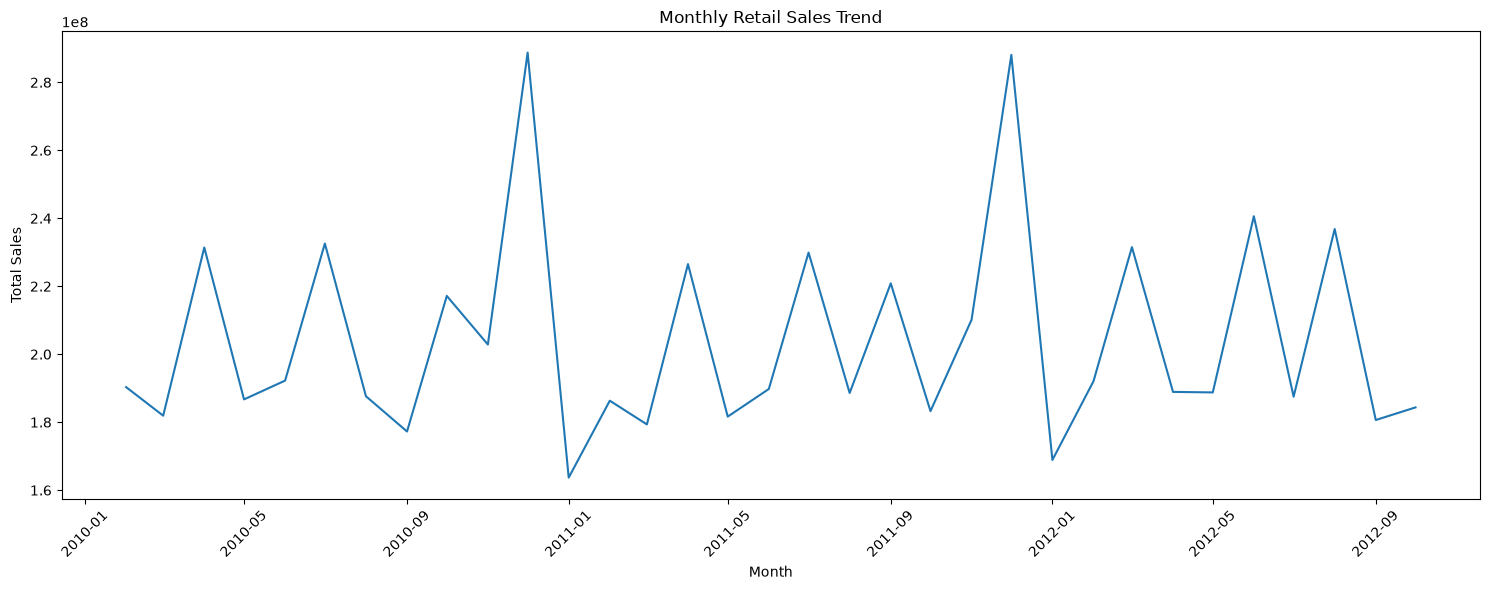

In [23]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales["Period"],
    monthly_sales["Weekly_Sales"]
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
monthly_seasonality = (
    df.groupby("Month")["Weekly_Sales"]
      .mean()
      .sort_values(ascending=False)
)

display(monthly_seasonality)

Month
12    19355.702141
11    17491.031424
6     16326.137002
8     16062.516933
2     16008.779217
7     15861.419650
5     15776.337202
4     15650.338357
3     15416.657597
10    15243.855576
9     15095.886154
1     14126.075111
Name: Weekly_Sales, dtype: float64

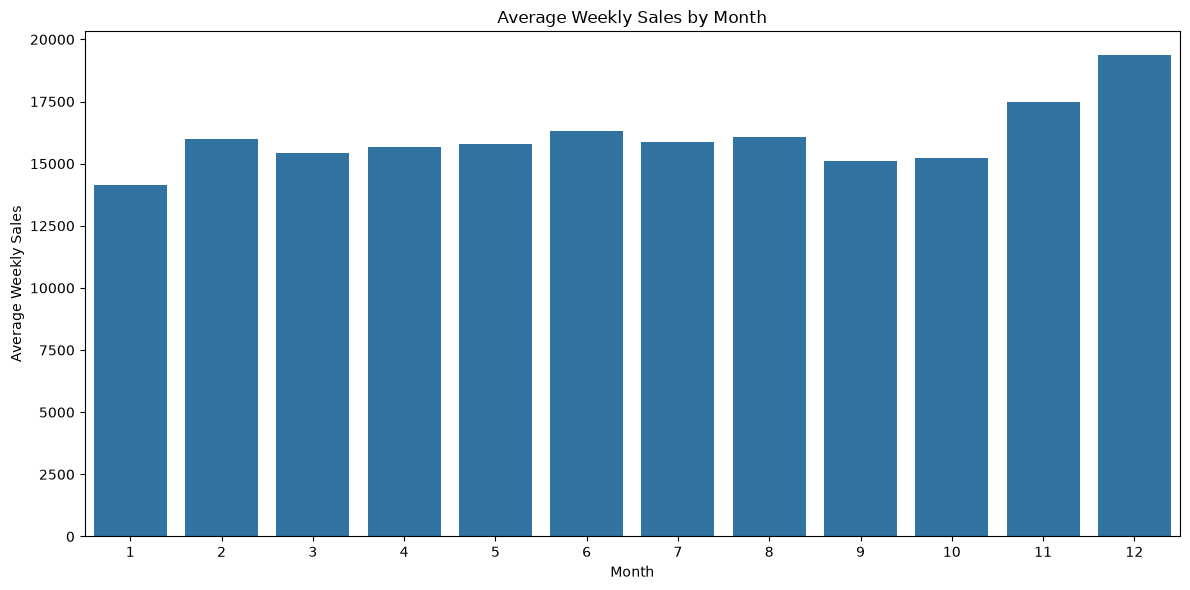

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_seasonality.index,
    y=monthly_seasonality.values
)

plt.title("Average Weekly Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")

plt.tight_layout()
plt.show()

In [26]:
print("Top 3 months by average sales:")

display(
    monthly_seasonality.head(3)
)

Top 3 months by average sales:


Month
12    19355.702141
11    17491.031424
6     16326.137002
Name: Weekly_Sales, dtype: float64

In [27]:
print("Bottom 3 months by average sales:")

display(
    monthly_seasonality.tail(3)
)

Bottom 3 months by average sales:


Month
10    15243.855576
9     15095.886154
1     14126.075111
Name: Weekly_Sales, dtype: float64

In [28]:
holiday_analysis = (
    df.groupby("IsHoliday")["Weekly_Sales"]
      .agg(["mean", "sum", "count"])
)

display(holiday_analysis)

,mean,sum,count
IsHoliday,,,
False,15901.445069,6.231919e+09,391909
True,17035.823187,5.052996e+08,29661


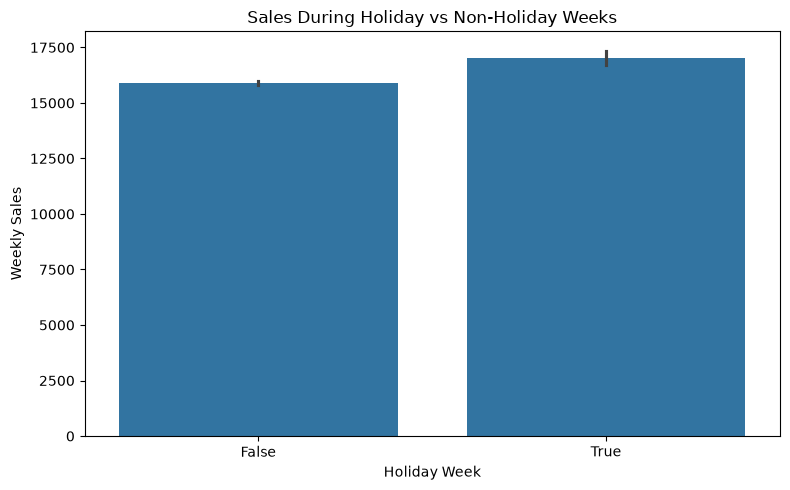

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="IsHoliday",
    y="Weekly_Sales"
)

plt.title("Sales During Holiday vs Non-Holiday Weeks")
plt.xlabel("Holiday Week")
plt.ylabel("Weekly Sales")

plt.tight_layout()
plt.show()

In [30]:
store_sales = (
    df.groupby("Store")["Weekly_Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 Stores:")
display(store_sales.head(10))

Top 10 Stores:


Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Weekly_Sales, dtype: float64

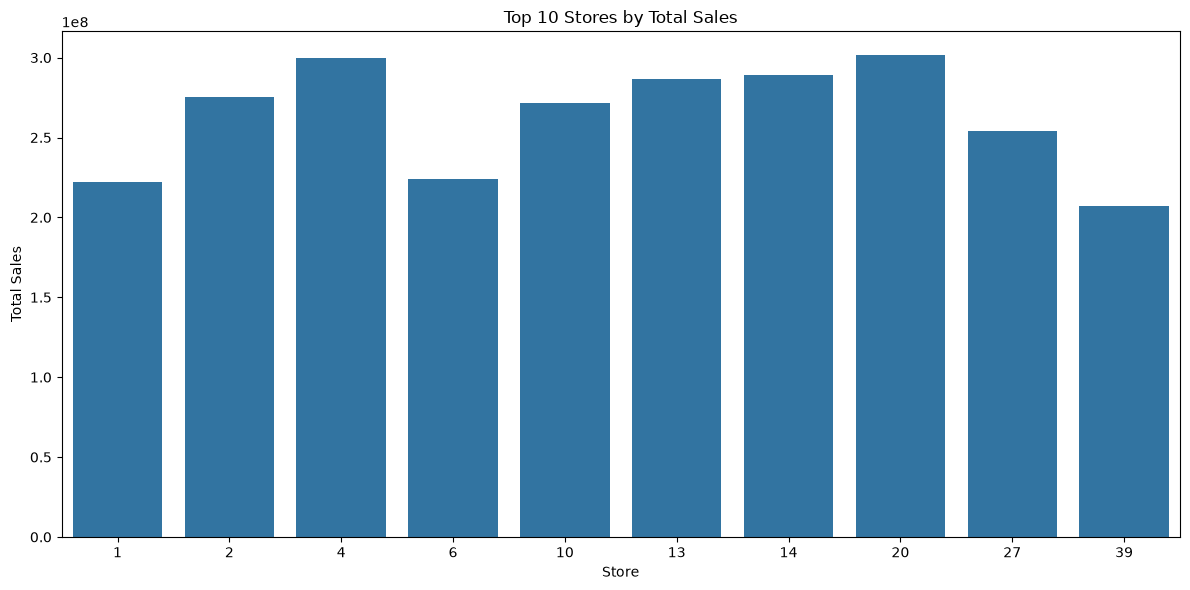

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=store_sales.head(10).index,
    y=store_sales.head(10).values
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [32]:
department_sales = (
    df.groupby("Dept")["Weekly_Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Top 10 Departments:")
display(department_sales.head(10))

Top 10 Departments:


Dept
92    4.839433e+08
95    4.493202e+08
38    3.931181e+08
72    3.057252e+08
90    2.910685e+08
40    2.889360e+08
2     2.806112e+08
91    2.167817e+08
13    1.973216e+08
8     1.942808e+08
Name: Weekly_Sales, dtype: float64

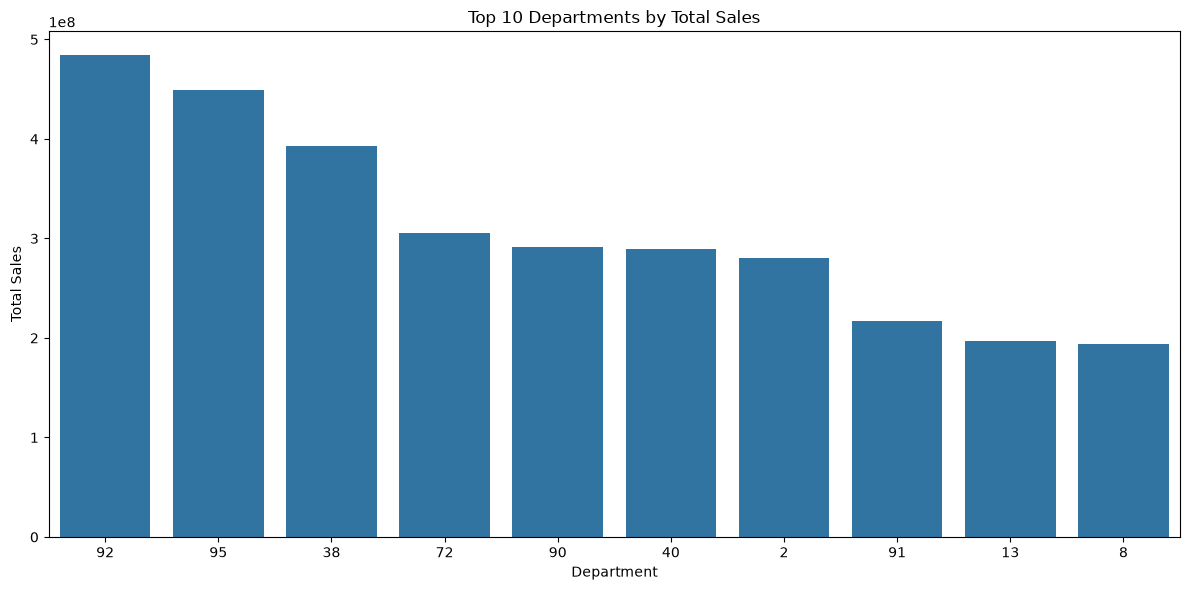

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=department_sales.head(10).index.astype(str),
    y=department_sales.head(10).values
)

plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Department")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [34]:
store_type_sales = (
    df.groupby("Type")["Weekly_Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(store_type_sales)

Type
A    4.331015e+09
B    2.000701e+09
C    4.055035e+08
Name: Weekly_Sales, dtype: float64

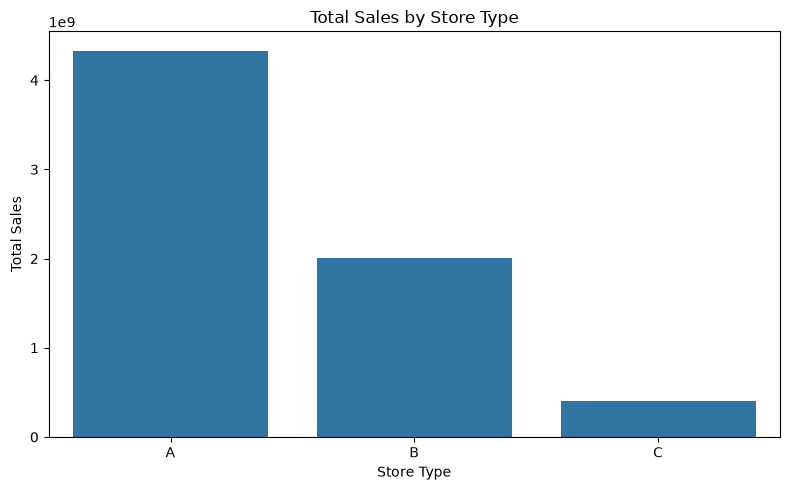

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=store_type_sales.index,
    y=store_type_sales.values
)

plt.title("Total Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [36]:
peak_weeks = (
    weekly_sales
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Peak Sales Weeks:")
display(peak_weeks)

Top 10 Peak Sales Weeks:


Date
2010-12-24    80931415.60
2011-12-23    76998241.31
2011-11-25    66593605.26
2010-11-26    65821003.24
2010-12-17    61820799.85
2011-12-16    60085695.94
2010-12-10    55666770.39
2011-12-09    55561147.70
2012-04-06    53502315.87
2012-07-06    51253021.88
Name: Weekly_Sales, dtype: float64

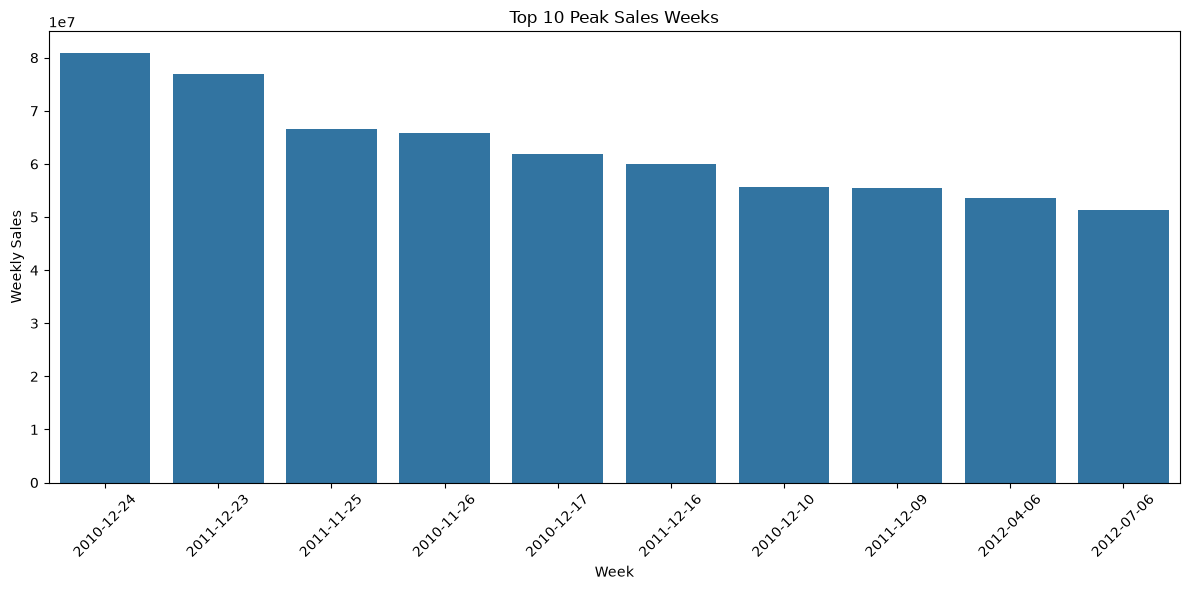

In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=peak_weeks.index.strftime("%Y-%m-%d"),
    y=peak_weeks.values
)

plt.title("Top 10 Peak Sales Weeks")
plt.xlabel("Week")
plt.ylabel("Weekly Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

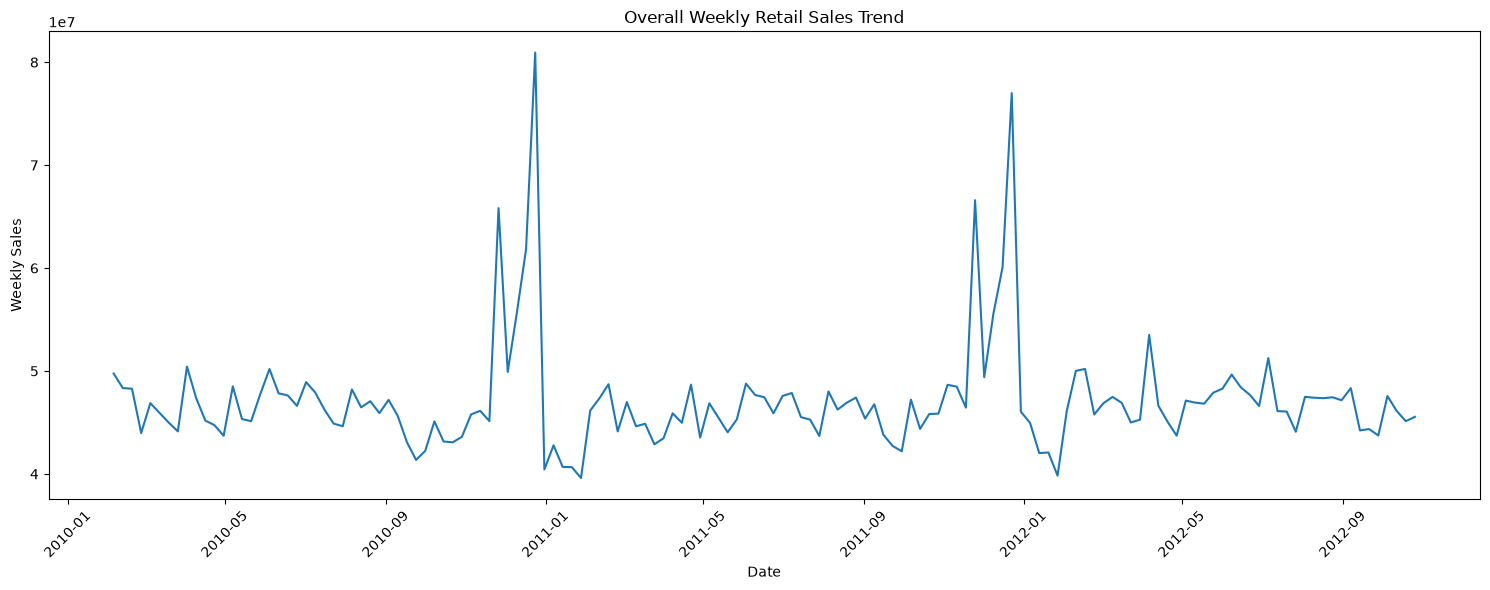

In [38]:
plt.figure(figsize=(15, 6))

plt.plot(
    weekly_sales.index,
    weekly_sales.values
)

plt.title("Overall Weekly Retail Sales Trend")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visuals/weekly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
ts = weekly_sales.copy()

ts = ts.sort_index()

print("Time Series Start:", ts.index.min())
print("Time Series End:", ts.index.max())
print("Number of observations:", len(ts))

display(ts.head())

Time Series Start: 2010-02-05 00:00:00
Time Series End: 2012-10-26 00:00:00
Number of observations: 143


Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Name: Weekly_Sales, dtype: float64

In [40]:
expected_dates = pd.date_range(
    start=ts.index.min(),
    end=ts.index.max(),
    freq="W-FRI"
)

missing_dates = expected_dates.difference(ts.index)

print("Expected weekly observations:", len(expected_dates))
print("Actual observations:", len(ts))
print("Missing weeks:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing dates:")
    print(missing_dates)

Expected weekly observations: 143
Actual observations: 143
Missing weeks: 0


In [41]:
train = ts.iloc[:-12]
test = ts.iloc[-12:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 131
Testing observations: 12

Training period:
2010-02-05 00:00:00 to 2012-08-03 00:00:00

Testing period:
2012-08-10 00:00:00 to 2012-10-26 00:00:00


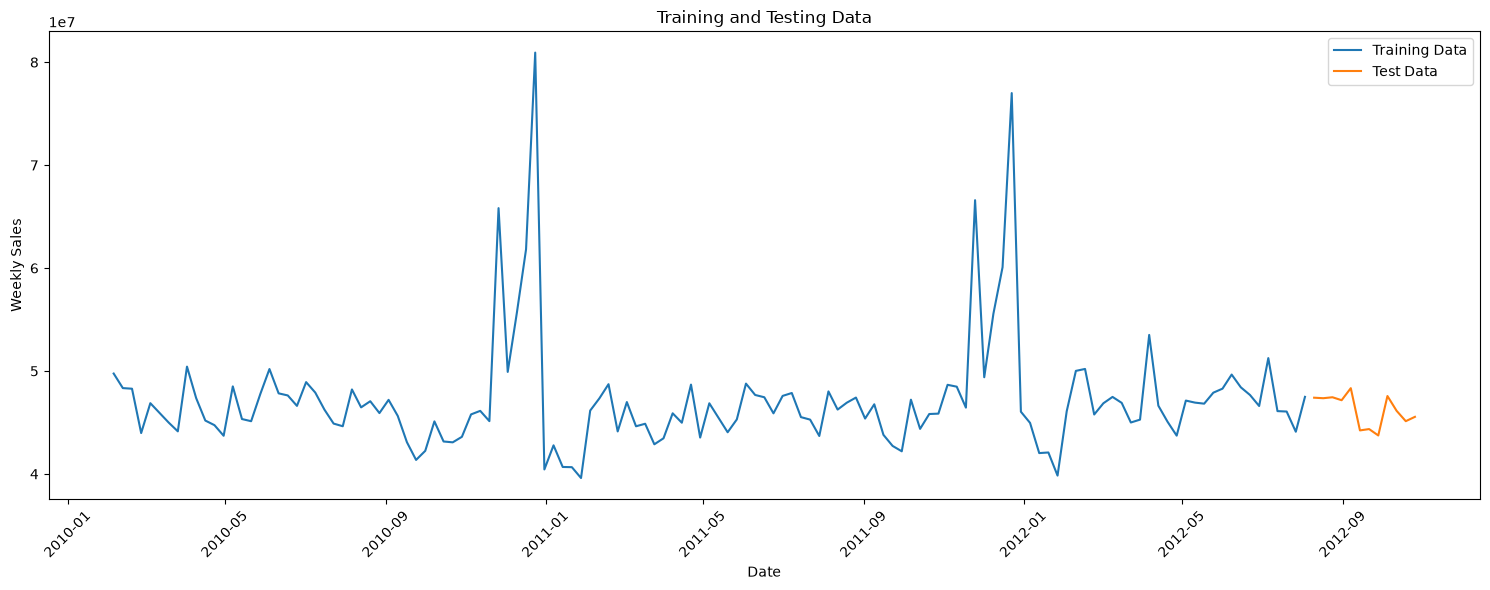

In [42]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train.values,
    label="Training Data"
)

plt.plot(
    test.index,
    test.values,
    label="Test Data"
)

plt.title("Training and Testing Data")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
window = 4

moving_average_value = train.rolling(
    window=window
).mean().iloc[-1]

moving_average_forecast = pd.Series(
    moving_average_value,
    index=test.index
)

print("Moving Average Forecast:")
display(moving_average_forecast)

Moving Average Forecast:


Date
2012-08-10    45935582.52
2012-08-17    45935582.52
2012-08-24    45935582.52
2012-08-31    45935582.52
2012-09-07    45935582.52
2012-09-14    45935582.52
2012-09-21    45935582.52
2012-09-28    45935582.52
2012-10-05    45935582.52
2012-10-12    45935582.52
2012-10-19    45935582.52
2012-10-26    45935582.52
dtype: float64

In [44]:
mae_ma = mean_absolute_error(
    test,
    moving_average_forecast
)

rmse_ma = np.sqrt(
    mean_squared_error(
        test,
        moving_average_forecast
    )
)

print(f"Moving Average MAE : {mae_ma:,.2f}")
print(f"Moving Average RMSE: {rmse_ma:,.2f}")

Moving Average MAE : 1,378,075.16
Moving Average RMSE: 1,512,787.36


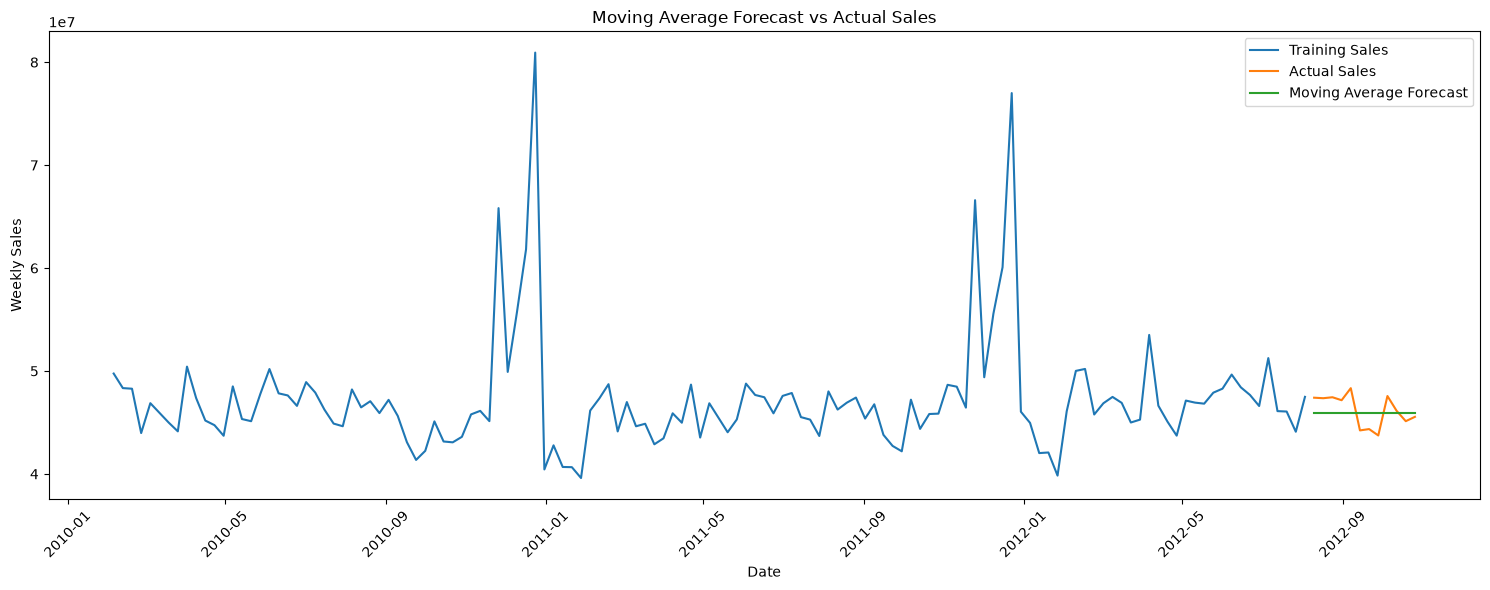

In [45]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train.values,
    label="Training Sales"
)

plt.plot(
    test.index,
    test.values,
    label="Actual Sales"
)

plt.plot(
    moving_average_forecast.index,
    moving_average_forecast.values,
    label="Moving Average Forecast"
)

plt.title("Moving Average Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [46]:
model = ARIMA(
    train,
    order=(1, 1, 1)
)

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  131
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2209.157
Date:                Mon, 02 Nov 2026   AIC                           4424.315
Time:                        00:29:07   BIC                           4432.917
Sample:                    02-05-2010   HQIC                          4427.810
                         - 08-03-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4538      0.076      5.999      0.000       0.306       0.602
ma.L1         -0.9725      0.043    -22.847      0.000      -1.056      -0.889
sigma2      3.333e+13   1.02e-15   3.27e+28      0.0

In [47]:
arima_predictions = model_fit.forecast(
    steps=len(test)
)

arima_predictions.index = test.index

print("ARIMA Predictions:")
display(arima_predictions)

ARIMA Predictions:


Date
2012-08-10    4.741502e+07
2012-08-17    4.738286e+07
2012-08-24    4.736826e+07
2012-08-31    4.736164e+07
2012-09-07    4.735863e+07
2012-09-14    4.735727e+07
2012-09-21    4.735665e+07
2012-09-28    4.735637e+07
2012-10-05    4.735624e+07
2012-10-12    4.735619e+07
2012-10-19    4.735616e+07
2012-10-26    4.735615e+07
Name: predicted_mean, dtype: float64

In [48]:
mae_arima = mean_absolute_error(
    test,
    arima_predictions
)

rmse_arima = np.sqrt(
    mean_squared_error(
        test,
        arima_predictions
    )
)

print(f"ARIMA MAE : {mae_arima:,.2f}")
print(f"ARIMA RMSE: {rmse_arima:,.2f}")

ARIMA MAE : 1,377,593.04
ARIMA RMSE: 1,887,425.85


In [49]:
model_comparison = pd.DataFrame({
    "Model": [
        "Moving Average",
        "ARIMA"
    ],
    "MAE": [
        mae_ma,
        mae_arima
    ],
    "RMSE": [
        rmse_ma,
        rmse_arima
    ]
})

display(model_comparison)

,Model,MAE,RMSE
0,Moving Average,1.378075e+06,1.512787e+06
1,ARIMA,1.377593e+06,1.887426e+06


In [50]:
if mae_arima < mae_ma:
    print("ARIMA performs better based on MAE.")
else:
    print("Moving Average performs better based on MAE.")

ARIMA performs better based on MAE.


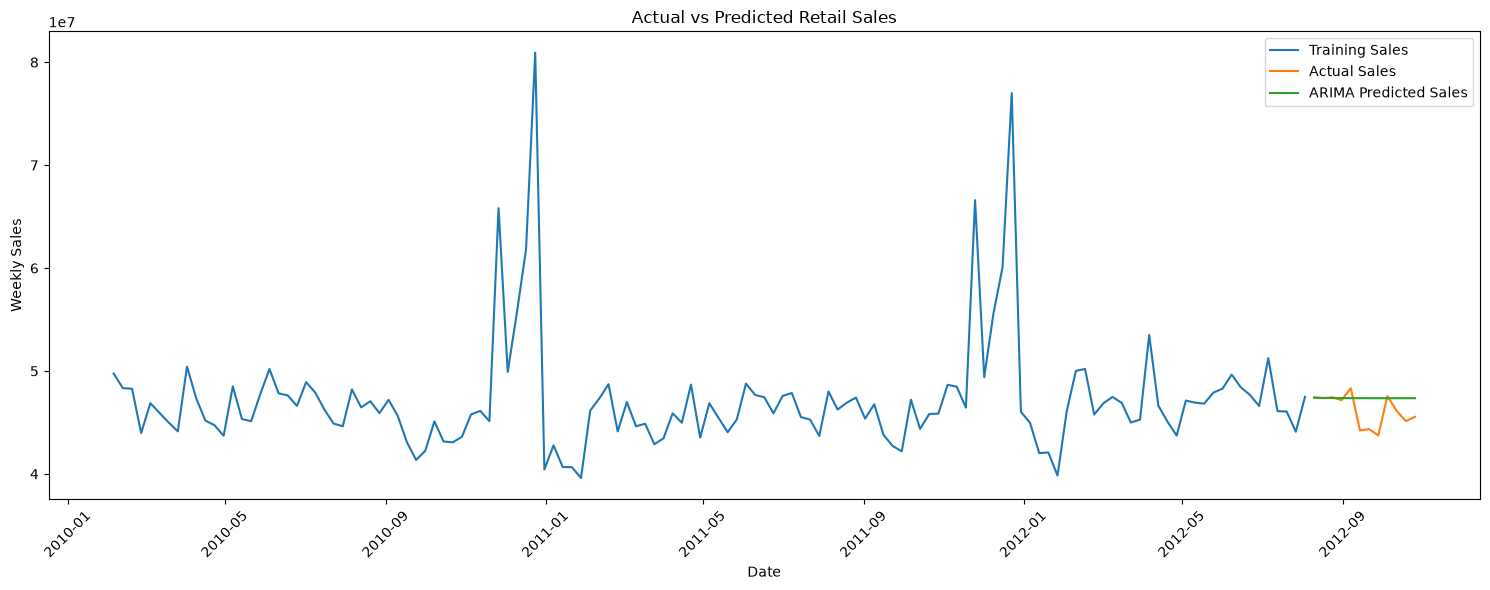

In [51]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train.values,
    label="Training Sales"
)

plt.plot(
    test.index,
    test.values,
    label="Actual Sales"
)

plt.plot(
    arima_predictions.index,
    arima_predictions.values,
    label="ARIMA Predicted Sales"
)

plt.title("Actual vs Predicted Retail Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [52]:
plt.savefig(
    "../visuals/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1200x600 with 0 Axes>

In [53]:
final_model = ARIMA(
    ts,
    order=(1, 1, 1)
)

final_model_fit = final_model.fit()

print("Final ARIMA model trained successfully.")

Final ARIMA model trained successfully.


In [59]:
future_forecast = final_model_fit.forecast(steps=12)

forecast_df = pd.DataFrame({
    "Date": future_forecast.index,
    "Forecasted_Sales": future_forecast.values
})

forecast_df["Forecasted_Sales"] = forecast_df["Forecasted_Sales"].round(2)

display(forecast_df)

,Date,Forecasted_Sales
0,2012-11-02,46312383.23
1,2012-11-09,46662431.79
2,2012-11-16,46821925.83
3,2012-11-23,46894596.74
4,2012-11-30,46927708.08
5,2012-12-07,46942794.73
6,2012-12-14,46949668.72
7,2012-12-21,46952800.75
8,2012-12-28,46954227.80
9,2013-01-04,46954878.02


In [60]:
average_sales = ts.mean()

print(f"Historical Average Weekly Sales: ${average_sales:,.2f}")

Historical Average Weekly Sales: $47,113,419.49


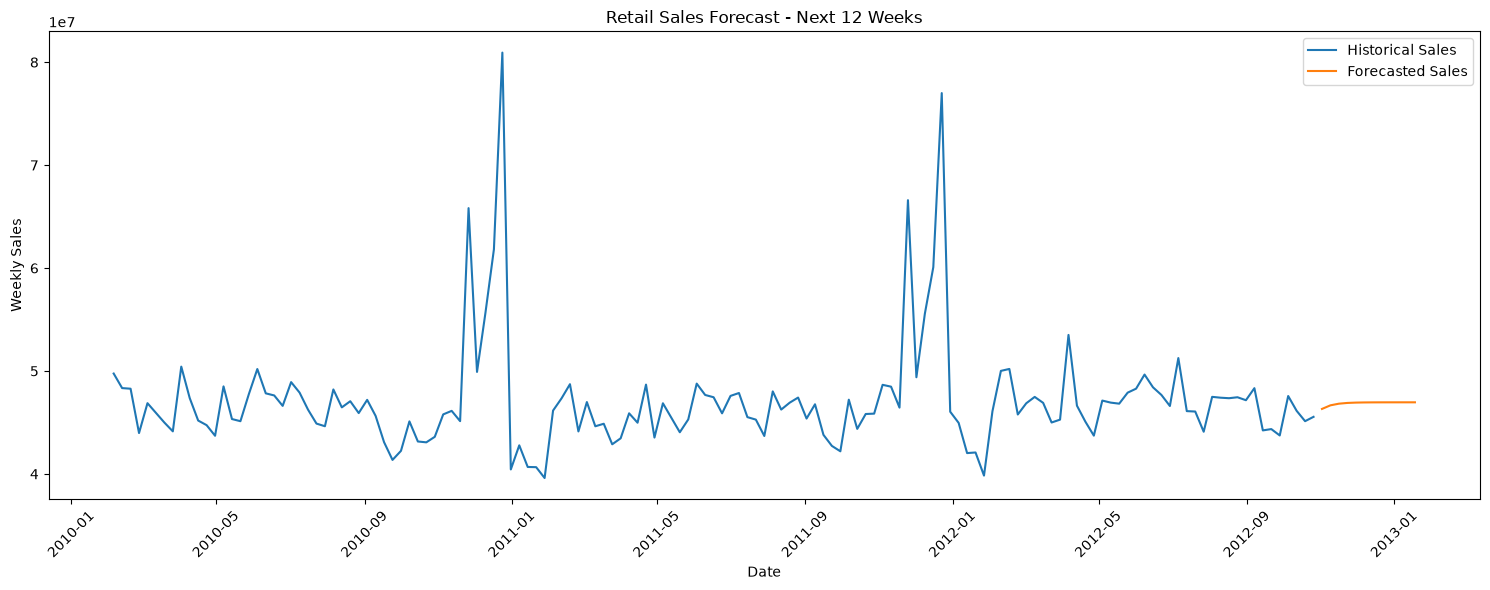

In [55]:
plt.figure(figsize=(15, 6))

plt.plot(
    ts.index,
    ts.values,
    label="Historical Sales"
)

plt.plot(
    future_forecast.index,
    future_forecast.values,
    label="Forecasted Sales"
)

plt.title("Retail Sales Forecast - Next 12 Weeks")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [56]:
plt.savefig(
    "../visuals/future_sales_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1200x600 with 0 Axes>

In [57]:
average_sales = ts.mean()

print(f"Historical Average Weekly Sales: ${average_sales:,.2f}")

Historical Average Weekly Sales: $47,113,419.49


In [61]:
forecast_df["Demand_Level"] = np.where(
    forecast_df["Forecasted_Sales"] > average_sales * 1.10,
    "High Demand",
    np.where(
        forecast_df["Forecasted_Sales"] < average_sales * 0.90,
        "Low Demand",
        "Normal Demand"
    )
)

display(forecast_df)

,Date,Forecasted_Sales,Demand_Level
0,2012-11-02,46312383.23,Normal Demand
1,2012-11-09,46662431.79,Normal Demand
2,2012-11-16,46821925.83,Normal Demand
3,2012-11-23,46894596.74,Normal Demand
4,2012-11-30,46927708.08,Normal Demand
5,2012-12-07,46942794.73,Normal Demand
6,2012-12-14,46949668.72,Normal Demand
7,2012-12-21,46952800.75,Normal Demand
8,2012-12-28,46954227.80,Normal Demand
9,2013-01-04,46954878.02,Normal Demand


In [62]:
print("Inventory Planning Recommendations\n")

for _, row in forecast_df.iterrows():
    if row["Demand_Level"] == "High Demand":
        recommendation = "Increase inventory and replenish stock early."
    elif row["Demand_Level"] == "Low Demand":
        recommendation = "Maintain lower inventory and avoid overstocking."
    else:
        recommendation = "Maintain normal inventory and replenishment levels."

    print(
        f"{row['Date'].date()} | "
        f"${row['Forecasted_Sales']:,.2f} | "
        f"{row['Demand_Level']} | "
        f"{recommendation}"
    )

Inventory Planning Recommendations

2012-11-02 | $46,312,383.23 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-11-09 | $46,662,431.79 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-11-16 | $46,821,925.83 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-11-23 | $46,894,596.74 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-11-30 | $46,927,708.08 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-12-07 | $46,942,794.73 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-12-14 | $46,949,668.72 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-12-21 | $46,952,800.75 | Normal Demand | Maintain normal inventory and replenishment levels.
2012-12-28 | $46,954,227.80 | Normal Demand | Maintain normal inventory and replenishment levels.
2013-01-04 | $46,954,878.02 | Normal Demand | Maintain normal inventory and replen

In [63]:
forecast_df.to_csv("../data/future_sales_forecast.csv", index=False)

print("Forecast saved successfully.")

Forecast saved successfully.


In [64]:
import os

print("Data files:")
for file in os.listdir("../data"):
    print("-", file)

print("\nVisual files:")
for file in os.listdir("../visuals"):
    print("-", file)

Data files:
- Features data set.csv
- future_sales_forecast.csv
- merged_retail_sales.csv
- sales data-set.csv
- stores data-set.csv

Visual files:
- actual_vs_predicted.png
- future_sales_forecast.png
- weekly_sales_trend.png


In [65]:
print("MODEL COMPARISON")
display(model_comparison)

print("\nFORECAST RESULTS")
display(forecast_df)

print("\nHISTORICAL AVERAGE WEEKLY SALES:")
print(f"${average_sales:,.2f}")

MODEL COMPARISON


,Model,MAE,RMSE
0,Moving Average,1.378075e+06,1.512787e+06
1,ARIMA,1.377593e+06,1.887426e+06



FORECAST RESULTS


,Date,Forecasted_Sales,Demand_Level
0,2012-11-02,46312383.23,Normal Demand
1,2012-11-09,46662431.79,Normal Demand
2,2012-11-16,46821925.83,Normal Demand
3,2012-11-23,46894596.74,Normal Demand
4,2012-11-30,46927708.08,Normal Demand
5,2012-12-07,46942794.73,Normal Demand
6,2012-12-14,46949668.72,Normal Demand
7,2012-12-21,46952800.75,Normal Demand
8,2012-12-28,46954227.80,Normal Demand
9,2013-01-04,46954878.02,Normal Demand



HISTORICAL AVERAGE WEEKLY SALES:
$47,113,419.49
